# 07 – Model Features

Builds one row per hexagon with the features the model will use, plus the target
variable (whether the hexagon already has a bubble tea shop).

**Features** (measured from each hexagon's center)
| Feature | Meaning |
|---|---|
| `dist_station_m` | Distance to the nearest subway/LRT station |
| `dist_campus_m` | Distance to the nearest major campus |
| `high_schools_1km` | High schools within 1 km |
| `food_places_500m` | Food & drink places within 500 m, excluding bubble tea shops |
| `catchment_pop` | Residents in the hexagon and its 6 neighbours (~1 km) |
| `catchment_15_34` | Residents aged 15–34 in the same area |
| `median_hh_income`, `share_15_34`, `pop_density` | From the census (notebook 04) |

**Target:** `has_bubble_tea`, which is 1 if the hexagon contains at least one shop.
94 of 846 land hexagons (11%), so the classes are imbalanced.

**Design decisions**
- **Avoiding leakage:** bubble tea shops are removed from the food-places count, so the
  feature doesn't partly measure the target.
- **Competitors are not a model input:** `competitors_1km` (shops nearby, excluding the
  hexagon's own) is kept for the final ranking step. Using it as an input would mostly
  teach the model that shops cluster near shops, without explaining why a location is good.
- **Catchment uses H3 neighbours** instead of walk-time areas, since road network
  downloads weren't available. Lake hexagons (<10% land) are excluded.

**Checks**
- 174 of 178 shops assigned to hexagons (the rest fall at the city edge or on water).

**Limitations**
- OpenStreetMap is mapped more thoroughly downtown than in the suburbs, so
  `food_places_500m` partly reflects mapping coverage, not just real activity.

**Output:** `data/processed/model_features.gpkg`

In [1]:
import geopandas as gpd
import pandas as pd
import h3

P = "../data/processed/"
hexes = gpd.read_file(P + "hex_features.gpkg")
stations = gpd.read_file(P + "stations.gpkg")
high_schools = gpd.read_file(P + "high_schools.gpkg")
campuses = gpd.read_file(P + "campuses.gpkg")
food = gpd.read_file(P + "food_places.gpkg")
bubble = gpd.read_file(P + "bubble_tea.gpkg")

# Drop hexagons that are mostly lake
hexes = hexes[hexes["land_share"] >= 0.1].reset_index(drop=True)
print("Land hexagons:", len(hexes))

# Hexagon center points, used to measure distances
centers = hexes[["h3_id", "geometry"]].copy()
centers["geometry"] = hexes.geometry.centroid

Land hexagons: 846


In [2]:
def nearest_distance(points):
    """Distance (m) from each hexagon center to the nearest point."""
    joined = gpd.sjoin_nearest(centers, points[["geometry"]], distance_col="dist")
    return joined.groupby("h3_id")["dist"].min()


def count_within(points, radius):
    """Number of points within `radius` metres of each hexagon center."""
    circles = centers.copy()
    circles["geometry"] = centers.buffer(radius)
    joined = gpd.sjoin(circles, points[["geometry"]], predicate="contains")
    return joined.groupby("h3_id").size()

In [3]:
f = hexes.set_index("h3_id")

f["dist_station_m"] = nearest_distance(stations)
f["dist_campus_m"] = nearest_distance(campuses)
f["high_schools_1km"] = count_within(high_schools, 1000)

# Commercial activity: food and drink places nearby, NOT counting bubble tea shops
# (otherwise the feature would partly measure the thing we're trying to predict)
f["food_places_500m"] = count_within(food, 500) - count_within(bubble, 500).reindex(f.index, fill_value=0)

# Hexagons with nothing nearby get no row from the join, so fill those with 0
count_cols = ["high_schools_1km", "food_places_500m"]
f[count_cols] = f[count_cols].fillna(0)

f[["dist_station_m", "dist_campus_m", "high_schools_1km", "food_places_500m"]].describe().round(0)

,dist_station_m,dist_campus_m,high_schools_1km,food_places_500m
count,846.0,846.0,846.0,846.0
mean,3223.0,4410.0,2.0,9.0
std,3196.0,2126.0,3.0,23.0
min,36.0,76.0,0.0,0.0
25%,1050.0,2787.0,0.0,0.0
50%,2118.0,4395.0,1.0,2.0
75%,4031.0,6028.0,2.0,9.0
max,15069.0,9799.0,22.0,295.0


Text(0.5, 1.0, 'Food & drink places within 500 m')

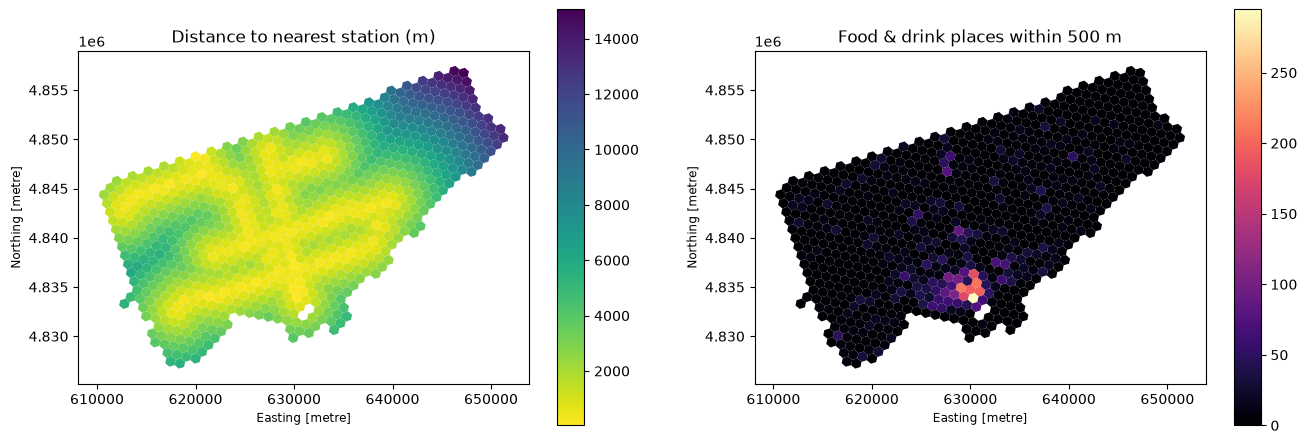

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
gpd.GeoDataFrame(f, geometry="geometry").plot(
    column="dist_station_m", cmap="viridis_r", legend=True, ax=axes[0])
axes[0].set_title("Distance to nearest station (m)")
gpd.GeoDataFrame(f, geometry="geometry").plot(
    column="food_places_500m", cmap="magma", legend=True, ax=axes[1])
axes[1].set_title("Food & drink places within 500 m")

In [5]:
def ring_sum(col, k=1):
    """Sum a column over each hexagon and its neighbours (k rings out)."""
    s = f[col]
    return pd.Series({cell: s.reindex(list(h3.grid_disk(cell, k))).sum() for cell in f.index})

f["catchment_pop"] = ring_sum("population")
f["catchment_15_34"] = ring_sum("age_15_34")

f[["catchment_pop", "catchment_15_34"]].describe().round(0)

,catchment_pop,catchment_15_34
count,846.0,846.0
mean,22495.0,6550.0
std,15776.0,6441.0
min,12.0,9.0
25%,12851.0,3316.0
50%,20201.0,5254.0
75%,28502.0,7803.0
max,118545.0,54391.0


In [6]:
# Which hexagon each bubble tea shop falls in
in_hex = gpd.sjoin(bubble, hexes[["h3_id", "geometry"]], predicate="within").groupby("h3_id").size()

f["bubble_tea_count"] = in_hex.reindex(f.index, fill_value=0)
f["has_bubble_tea"] = (f["bubble_tea_count"] > 0).astype(int)

# Competitors nearby, NOT counting the hexagon's own shops
f["competitors_1km"] = (
    count_within(bubble, 1000).reindex(f.index, fill_value=0) - f["bubble_tea_count"]
)

print("Shops assigned to hexagons:", f["bubble_tea_count"].sum(), "of", len(bubble))
print(f["has_bubble_tea"].value_counts())

Shops assigned to hexagons: 174 of 178
has_bubble_tea
0    752
1     94
Name: count, dtype: int64


Saved 846 hexagons with 16 columns


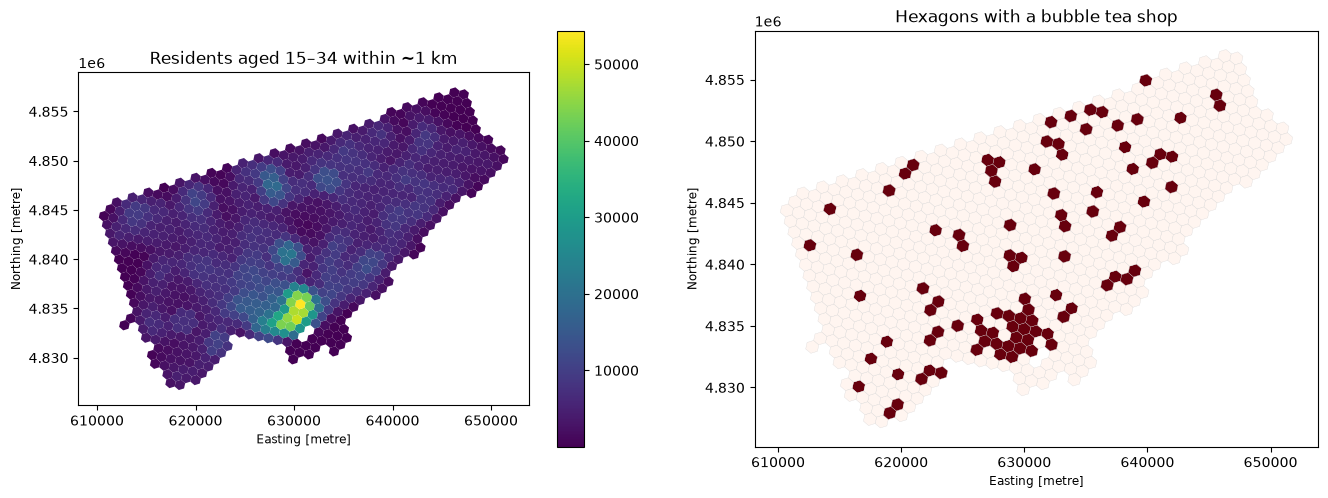

In [7]:
out = gpd.GeoDataFrame(f.reset_index(), geometry="geometry", crs=hexes.crs)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
out.plot(column="catchment_15_34", cmap="viridis", legend=True, ax=axes[0])
axes[0].set_title("Residents aged 15–34 within ~1 km")
out.plot(column="has_bubble_tea", cmap="Reds", ax=axes[1], edgecolor="lightgrey", linewidth=0.2)
axes[1].set_title("Hexagons with a bubble tea shop")

out.to_file(P + "model_features.gpkg", driver="GPKG")
print("Saved", len(out), "hexagons with", out.shape[1] - 2, "columns")